# DHSort: haploid maize seed classification (inference reproduction)

**Paper:** Sabadin, F., Galli, G., Borsato Jr, R., Gevartosky, R., Campos, G.R., Fritsche-Neto, R. (2021).
*Improving the identification of haploid maize seeds using convolutional neural networks.*
**Crop Science** 61(4):2387–2397. DOI: [10.1002/csc2.20487](https://doi.org/10.1002/csc2.20487)

**Author code:** [sabadinfelipe/DHsort](https://github.com/sabadinfelipe/DHsort), pinned commit `ef9cbe55cf80ffc8f1e99e3b3ca4d60976174b51` (MIT license).

**Scope of this notebook:** a faithful, minimal reproduction of the authors' **released inference workflow** —
`python DHsort.py` — which loads the trained `model.h5`, classifies the **60 bundled example seed images**
(30 diploid, 30 haploid) as **D** (diploid) or **H** (haploid), and writes `output.csv`.
Training, the paper's dataset-level accuracy (94.39% reported in the abstract), and the full-text methods are **out of scope**;
the version-of-record full text was not retrievable (Wiley 403, no PMC copy), and every operation reproduced here is
specified by the pinned `DHsort.py` and README instead.

**Execution status:** validated end-to-end on a fresh Google Colab CPU runtime (see final cells / report).

**日本語:** このNotebookは、論文の著者らが公開した推論スクリプト `DHsort.py` と学習済みモデル `model.h5` をそのまま実行し、
同梱の60枚の種子画像（倍数性判定：二倍体D／単為生殖ハプロイドH）を分類する最小再現です。学習や論文記載の精度評価（94.39%）は対象外です。
CPUランタイムで動作します。

## Runtime selection — use a CPU runtime (Runtime ▸ Change runtime type ▸ CPU)

The method is a single forward pass of a ~11 MB Keras CNN over 60 images of 100×100 pixels.
The author's script has no GPU-specific code, and CPU inference of this workload takes seconds,
so a **CPU runtime is sufficient and recommended**. A GPU runtime also works but adds nothing scientifically.
Expected wall time: a few minutes including Colab startup, ~12 MB of downloads (60 JPEGs ≈ 0.9 MB + `model.h5` ≈ 11 MB).

**日本語:** 「ランタイム ▸ ランタイムのタイプを変更」で **CPU** を選択してください（GPUは不要です）。
所要時間は数分、ダウンロードは約12 MBです。

## 1. Environment check

**Expected result:** prints Python / TensorFlow / Keras versions and available devices.
The authors require Python 3 + TensorFlow/Keras + numpy + pandas (README "Requirements").
Colab's preinstalled TensorFlow is used; TensorFlow is installed only if missing.
On a CPU runtime no GPU will be listed — that is expected and sufficient.

**日本語:** Python・TensorFlow・Kerasのバージョンと利用可能なデバイスを表示します。TensorFlowが無い場合のみインストールします。

In [ ]:
import platform, sys

try:
    import tensorflow as tf
except ImportError:
    print("TensorFlow not found; installing tensorflow-cpu...")
    get_ipython().system('%pip install -q tensorflow-cpu')
    import tensorflow as tf

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("Keras:", tf.keras.__version__)
print("Devices:", [d.name for d in tf.config.list_physical_devices()])
if platform.machine() not in ("x86_64", "aarch64", "arm64"):
    print("Warning: unexpected architecture:", platform.machine())

Python: 3.13.16
TensorFlow: 2.21.0
Keras: 3.13.2
Devices: ['/physical_device:CPU:0']


## 2. Acquire the pinned inputs (60 example images + model.h5)

Downloads **only** the files required by the minimal reproduction from the author repository at the pinned
commit `ef9cbe55cf80ffc8f1e99e3b3ca4d60976174b51`:

- `dataset/*.jpg` — the 60 example seed images (README step 2: "60 seed image examples (30 haploids and 30 diploida)")
- `model.h5` — the trained Keras model (expected size 10,962,160 B; git blob SHA-1 verified below)

Route: one public GitHub **tree API** call for the exact pinned commit (rejected if truncated), then per-file
downloads from pinned `raw.githubusercontent.com` URLs. Every payload is verified against its **git blob SHA-1**
(`sha1("blob <size>\0" + bytes)`) and byte size from that tree, which also rejects any Git LFS pointer file.
All bytes stay in the Colab VM under `/content`. **日本語:** ピン留めしたコミットから例画像60枚と`model.h5`のみをGitHub経由で取得し、
各ファイルのgit blob SHA-1とサイズを検証します（LFSポインタでないことも確認）。

In [ ]:
import hashlib, json, os, time, urllib.request

COMMIT = "ef9cbe55cf80ffc8f1e99e3b3ca4d60976174b51"
REPO = "sabadinfelipe/DHsort"
RAW = f"https://raw.githubusercontent.com/{REPO}/{COMMIT}"
DATASET_DIR = "dataset"
MODEL_PATH = "model.h5"
MODEL_EXPECTED = {"sha1_blob": "bdce29af1cf999ae2a8b6604f20e0305af934431", "size": 10962160}


def blob_sha1(data: bytes) -> str:
    h = hashlib.sha1()
    h.update(b"blob %d\0" % len(data))
    h.update(data)
    return h.hexdigest()


def fetch(url: str, timeout: int = 120) -> bytes:
    with urllib.request.urlopen(url, timeout=timeout) as r:
        return r.read()


t0 = time.time()
tree_url = f"https://api.github.com/repos/{REPO}/git/trees/{COMMIT}?recursive=true"
req = urllib.request.Request(tree_url, headers={"Accept": "application/vnd.github+json"})
with urllib.request.urlopen(req, timeout=60) as r:
    tree = json.load(r)
assert not tree.get("truncated"), "GitHub tree listing was truncated; refusing to continue"

entries = [e for e in tree["tree"]
           if e["type"] == "blob" and e["path"].startswith("dataset/") and e["path"].endswith(".jpg")]
assert len(entries) == 60, f"expected 60 example images at pinned commit, got {len(entries)}"

os.makedirs(DATASET_DIR, exist_ok=True)
for e in entries:
    data = fetch(f"{RAW}/{e['path']}")
    assert len(data) == e["size"] and blob_sha1(data) == e["sha"], f"integrity check failed: {e['path']}"
    with open(e["path"], "wb") as f:
        f.write(data)

model_bytes = fetch(f"{RAW}/model.h5")
assert len(model_bytes) == MODEL_EXPECTED["size"] and blob_sha1(model_bytes) == MODEL_EXPECTED["sha1_blob"], \
    "model.h5 integrity check failed (size or git blob SHA-1)"
with open(MODEL_PATH, "wb") as f:
    f.write(model_bytes)

print(f"Downloaded and verified {len(entries)} example images + model.h5 "
      f"({len(model_bytes)/1e6:.1f} MB) in {time.time()-t0:.1f} s")
print("Provenance: https://github.com/" + REPO + " @ " + COMMIT)

Downloaded and verified 60 example images + model.h5 (11.0 MB) in 9.9 s
Provenance: https://github.com/sabadinfelipe/DHsort @ ef9cbe55cf80ffc8f1e99e3b3ca4d60976174b51


## 3. Validate the downloaded bytes

**Expected result:** 30 `diploid_*.jpg` + 30 `haploid_*.jpg`, all decodable by PIL,
each ≥1 KB (all blob SHA-1s were already checked against the pinned tree).
This confirms we have real, parseable seed images — not error pages or pointer files — before any model runs.

**日本語:** ダウンロードした画像が実際にPILで復号できること、クラス別枚数（30/30）を確認します。

In [ ]:
from pathlib import Path

from PIL import Image

paths = sorted(Path(DATASET_DIR).glob("*.jpg"))
classes = {"diploid": [], "haploid": []}
for p in paths:
    key = "diploid" if p.name.startswith("diploid_") else "haploid"
    assert p.name.split("_")[0] in classes, f"unexpected filename: {p.name}"
    classes[key].append(p)
    with Image.open(p) as im:
        im.verify()  # decode check; does not trust the extension

print(f"images: {len(paths)} (diploid={len(classes['diploid'])}, haploid={len(classes['haploid'])})")
sizes = sorted({Image.open(p).size for p in paths}, key=lambda s: (-s[0], -s[1]))
print("observed pixel sizes (top 5):", sizes[:5], "... total distinct:", len(sizes))

images: 60 (diploid=30, haploid=30)
observed pixel sizes (top 5): [(274, 274), (268, 268), (266, 266), (264, 264), (262, 262)] ... total distinct: 35


## 4. Input preview — the actual seed images

Displays a grid of **all 60 downloaded example images** (the exact inputs the model will classify),
sorted by filename. Titles show the filename; blue = `diploid_*`, orange = `haploid_*`.
Per the README, valid inputs are single seeds centered on a **black background** (R1-nj marker visible on haploids).
This is direct observation of the downloaded files, not a model result.

**日本語:** 分類対象の60枚すべてをサムネイル表示します（青=二倍体、橙=ハプロイド、ファイル名順）。著者READMEの入力仕様（黒背景・1種子中央）を確認できます。

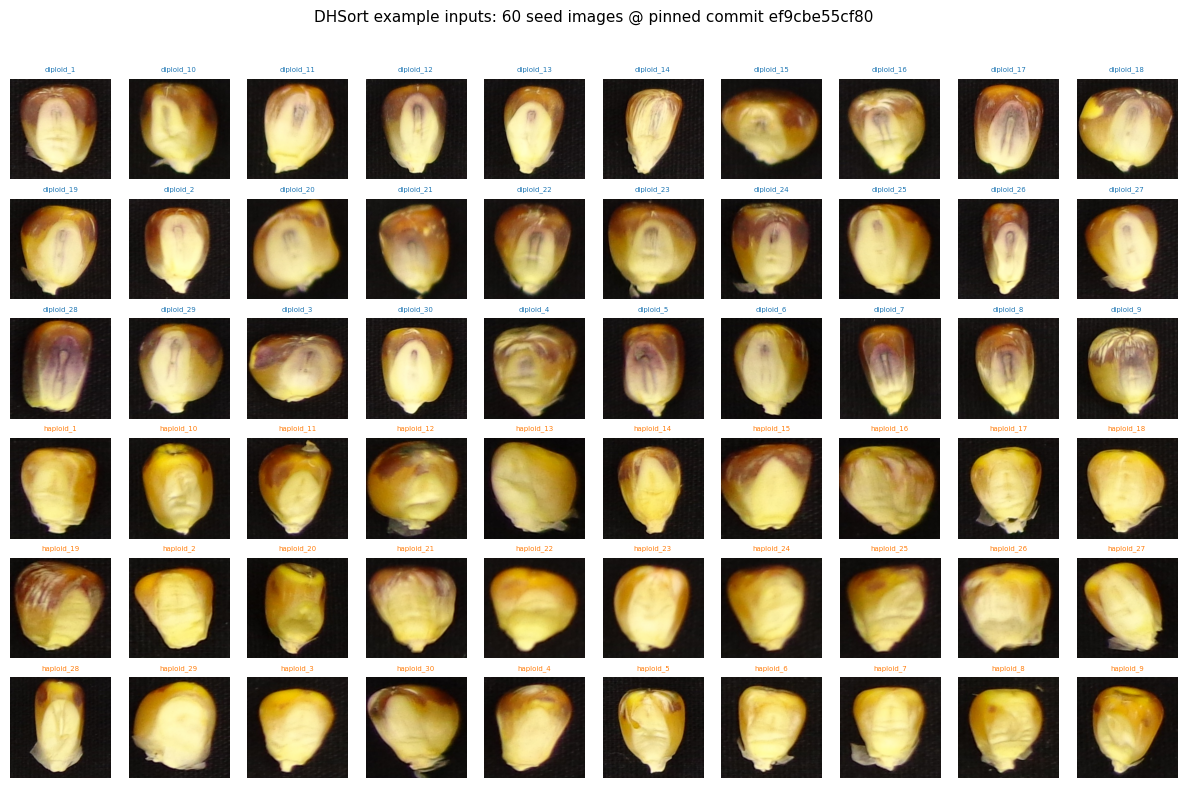

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(6, 10, figsize=(12, 8))
fig.suptitle("DHSort example inputs: 60 seed images @ pinned commit " + COMMIT[:12], fontsize=11)
for ax, p in zip(axes.ravel(), paths):
    with Image.open(p) as im:
        ax.imshow(im)
    ax.set_title(p.stem, fontsize=5, color="tab:blue" if p.stem.startswith("diploid") else "tab:orange")
    ax.axis("off")
for ax in axes.ravel()[len(paths):]:
    ax.axis("off")
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 5. Core inference — faithful port of the pinned `DHsort.py`

This cell reproduces the author script's operations in order: load every image with
`target_size=(100,100)` and `interpolation='bicubic'`, rescale by `/255`, load `model.h5`,
predict, threshold at 0.5, and map 0→**D** (diploid), 1→**H** (haploid).

Two **minimal compatibility adaptations** (values and thresholds unchanged), required because the 2021
script predates current NumPy/Keras and fails as-is on Colab:

1. `np.int` → `int` (`np.int` was removed in NumPy ≥ 1.24).
2. `tensorflow.keras.preprocessing.image.load_img` → `tensorflow.keras.utils.load_img`
   (`keras.preprocessing` was removed in Keras 3; the PIL-based loader is the same).

Everything else follows `DHsort.py` at commit `{C}` verbatim. Images are processed in sorted-filename order
(the author's `os.listdir` order is unspecified; each image is independent, so predictions are unaffected).
**日本語:** 著者スクリプトの処理（100×100・bicubicリサイズ、/255、model.h5読込、閾値0.5、0→D/1→H）をそのまま移植します。
現行NumPy/Kerasで動かすため `np.int`→`int` と画像読込APIの移行のみ最小限の互換修正を行いました。

In [ ]:
import numpy as np
import pandas as pd
from tensorflow import keras
from tensorflow.keras.utils import load_img, img_to_array  # adaptation 2 (was keras.preprocessing.image)

images = [os.path.join(DATASET_DIR, f) for f in sorted(os.listdir(DATASET_DIR)) if f.lower().endswith(".jpg")]

# preparing images (DHsort.py: target_size=(100,100), interpolation='bicubic')
images_input = np.array([img_to_array(load_img(img, target_size=(100, 100), interpolation="bicubic")) for img in images])
images_input /= 255  # rescaling (author's operation, verbatim)

# loading model (author's operation, verbatim)
trained_model = keras.models.load_model(MODEL_PATH)

# predictions (adaptation 1: np.int -> int; threshold 0.5 unchanged)
y_pred = trained_model.predict(images_input, verbose=0)
y_pred = (y_pred > 0.5).astype(int)
y_labels = ["D" if y == 0 else "H" for y in y_pred.ravel()]

print(f"model loaded: input {trained_model.input_shape}, output {trained_model.output_shape}")
print(f"predicted probability range over 60 images: {y_pred.ravel().min()}..{y_pred.ravel().max()}")
print("first 5 predictions:", list(zip([os.path.basename(i) for i in images[:5]], y_labels[:5])))

/usr/local/lib/python3.13/dist-packages/keras/src/optimizers/base_optimizer.py:86: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


model loaded: input (None, 100, 100, 3), output (None, 1)
predicted probability range over 60 images: 0..1
first 5 predictions: [('diploid_1.jpg', 'D'), ('diploid_10.jpg', 'D'), ('diploid_11.jpg', 'D'), ('diploid_12.jpg', 'D'), ('diploid_13.jpg', 'D')]


## 6. Results — `output.csv` (author's documented output)

The author README documents a two-column `output.csv` with `file_name` and `phenotype`
(**D** = diploid, **H** = haploid). The cell writes that exact file to `/content/output.csv`
and displays the full table. **日本語:** 著者のREADMEどおり `output.csv`（file_name, phenotype）を作成し表示します。

In [ ]:
file_names = [os.path.basename(i) for i in images]
predictions = pd.DataFrame()
predictions.insert(0, "file_name", file_names, True)
predictions.insert(1, "phenotype", y_labels, True)
predictions.to_csv("output.csv", index=False)
print(f"wrote output.csv with {len(predictions)} rows ({(predictions.phenotype == 'H').sum()} H, "
      f"{(predictions.phenotype == 'D').sum()} D)")
predictions

wrote output.csv with 60 rows (30 H, 30 D)


,file_name,phenotype
0,diploid_1.jpg,D
1,diploid_10.jpg,D
2,diploid_11.jpg,D
3,diploid_12.jpg,D
4,diploid_13.jpg,D
5,diploid_14.jpg,D
6,diploid_15.jpg,D
7,diploid_16.jpg,D
8,diploid_17.jpg,D
9,diploid_18.jpg,D


## 7. Consistency check against the bundled filename labels

The 60 examples ship with class names in their filenames (`diploid_*` / `haploid_*`), so we can compare the
model's output with those labels as a **consistency check on the bundled examples only**.
⚠️ These images are included in the authors' own repository and may overlap their training data; this agreement
rate is **not** the paper's reported 94.39% test accuracy and must not be cited as such.
The bar chart is an additional visualization created for this notebook, not an author figure.

**日本語:** ファイル名由来のラベルと予測の一致率を「同梱例に対する整合チェック」として示します（学習データとの重複があり得るため、
論文の94.39%とは比較できません）。棒グラフはこのNotebookで追加作成した可視化です。

,correct,n,mismatch
expected,,,
D,30,30,0
H,30,30,0


agreement with bundled filename labels: 100.0% (60/60)


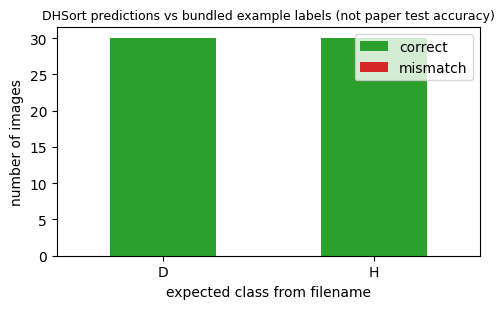

In [ ]:
import matplotlib.pyplot as plt

check = predictions.copy()
check["expected"] = ["D" if n.startswith("diploid_") else "H" for n in check.file_name]
check["match"] = check.phenotype == check.expected
summary = check.groupby("expected")["match"].agg(["sum", "count"])
summary["mismatch"] = summary["count"] - summary["sum"]
display(summary.rename(columns={"sum": "correct", "count": "n"}))
print(f"agreement with bundled filename labels: {check.match.mean()*100:.1f}% "
      f"({int(check.match.sum())}/{len(check)})")

fig, ax = plt.subplots(figsize=(5, 3.2))
summary[["sum", "mismatch"]].plot.bar(stacked=True, ax=ax, color=["tab:green", "tab:red"], rot=0)
ax.set_xlabel("expected class from filename")
ax.set_ylabel("number of images")
ax.set_title("DHSort predictions vs bundled example labels (not paper test accuracy)", fontsize=9)
ax.legend(["correct", "mismatch"])
fig.tight_layout()
plt.show()

if not check.match.all():
    print("mismatched files:")
    display(check.loc[~check.match, ["file_name", "phenotype", "expected"]])

## 8. Interpretation and limitations

- **What was reproduced:** the authors' released inference pipeline (pinned `DHsort.py` + `model.h5`) on the
  60 bundled example seeds, with the documented `output.csv` output. Executed fully in Colab on a CPU runtime.
- **What was not reproduced / known limitations:**
  - Training and the paper's dataset-level results (94.39% accuracy, 97.07% haploid sensitivity,
    91.71% diploid specificity from the abstract) — out of scope; the full-text methods were not retrievable
    (Wiley 403; no PMC copy), and the repo releases inference only.
  - The full 3,000-seed dataset is not public; only these 60 examples were released.
  - The agreement rate above is a consistency check that may include training images — **not** a test-set metric.
- **Provenance:** everything comes from commit `{C}` of sabadinfelipe/DHsort (MIT license);
  paper identity from DOI 10.1002/csc2.20487 (Crop Science 61(4), 2021).
  AI-generated guidance from the PhenoPaper investigation was used only to locate the repository; all operations
  were verified against the pinned code and README.

**日本語:** 本Notebookで再現したのは著者公開の推論パイプラインのみです。学習・論文のデータセット精度は対象外であり、
上記の一致率は学習画像を含み得る同梱例への整合チェックにすぎません。